# Exercise 1: Gaining First Insights into a Dataset

## Prelude

Throughout the semester, we will make extensive use of Jupyter notebooks for homework assignments.
They are widely used in data science and data engineering to work interactively on problems and showcase results.
Notebooks allow for the easy interleaving of code (primarily Python) and text (in Markdown) in cells. Cells can be executed independently but share a global state.
If you have never worked with Jupyter notebooks before, you will find plenty of tutorials online.

You are free to use [Google Colab](https://colab.research.google.com/) – a hosted version of Jupyter notebooks that you can use inside your browser without installing any Python packages – for your assignments.

If you want to run notebooks locally on your machine, we recommend using [virtual environments](https://docs.python.org/3/library/venv.html) (or similar solutions) to avoid package conflicts. You can create a virtual environment by running the following commands in a terminal:


```sh
python3 -m venv .venv         # Creates a folder '.venv' in the current directory, which contains the virtual environment
source .venv/bin/activate     # To redirect Python-related commands to the versions in .venv
```

When you install a package via `pip install <package>`, it is installed in the `.venv` directory rather than in your system-wide installation.

> Note: You need to run `source .venv/bin/activate` every time you open a new terminal. Otherwise, that terminal will use your system-wide Python installation.

Now, let's install the required packages for this exercise:
```sh
pip install pandas pyarrow jupyterlab jupysql duckdb duckdb-engine
```

## Introduction

In this first exercise, you will learn to use two fundamental tools from the data engineer’s toolbox: **GNU/UNIX tools** and **SQL**.

You might find them a bit dated—and you would be right. For example, SQL and `grep` were both first released in 1973, more than 50 years ago. However, they remain the *lingua franca* of data processing, making them essential to know. We do not want anyone to leave this class without knowing at least the basics.

You might ask: *"What about [Pandas](https://pandas.pydata.org/) (the Python package)?"* It is a widely used tool that enables quick data processing in Python. You will certainly encounter it at some point, especially in the data science domain. In data engineering, however, it is used less frequently, as you will quickly reach its limitations when processing larger datasets. Even more efficient implementations of the “DataFrames API” eventually reach their limits.

#### The Dataset
For this exercise, we will use the well-known "New York Taxi Dataset"—a publicly available dataset published by the city of New York that contains information about taxi rides. It is widely used in examples and benchmarks, so you will likely come across it again. It is also known for containing typical issues found in “dirty” datasets, which you will soon experience yourself.

This dataset is often used in research because it (a) is easy to work with, (b) contains real-world data, and (c) has a reasonable size. For this exercise, we will only use the data from August 2021.

Documentation for the dataset is available at <https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page>. In particular, see <https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf>.  
On the website, you will notice several mentions of the “Parquet format.” We will not use this format yet; we will discuss it later in the course. For now, we will convert the data to CSV format so that you can manually inspect the file.


In [123]:
import pandas as pd

# Download the New York Taxi trip dataset and convert it to CSV
df = pd.read_parquet('https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2021-08.parquet')
df.to_csv('yellow_tripdata_2021-08.csv', index=False)

PermissionError: [Errno 13] Permission denied: 'yellow_tripdata_2021-08.csv'

#### Task 1
Familiarize yourself with the dataset. Open the CSV file and take a look at it. Also, review the documentation provided above to understand the meaning of each column.

Try to answer the following questions:
1. Is this a binary or a text file format?  
2. Is this data relational or non-relational?  
3. How is the data formatted, e.g., how are dates represented?  
4. Are there any obvious missing values? How are missing values represented?  


#### Task 2

Let’s begin by gaining an overview and building foundational data-handling skills with UNIX tools. I will start with a few examples, and you can follow along.  
We can execute terminal commands directly inside Jupyter notebooks by adding the `%%bash` magic at the beginning of a cell. Alternatively, you can use `%bash` in front of a single line or `!` followed by the command.


In [ ]:
%%bash
# Let's inspect the dataset:
head -n 5 yellow_tripdata_2021-08.csv

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
2,2021-08-01 00:04:06,2021-08-01 00:26:07,2.0,3.52,1.0,N,43,42,1,16.5,0.5,0.5,5.08,0.0,0.3,25.38,2.5,0.0
1,2021-08-01 00:34:14,2021-08-01 00:43:02,0.0,2.1,1.0,N,79,233,2,9.0,3.0,0.5,0.0,0.0,0.3,12.8,2.5,0.0
1,2021-08-01 00:43:53,2021-08-01 00:55:04,0.0,1.4,1.0,N,170,90,1,8.5,3.0,0.5,3.05,0.0,0.3,15.35,2.5,0.0
1,2021-08-01 00:53:19,2021-08-01 00:55:34,1.0,0.4,1.0,N,229,229,1,4.0,3.0,0.5,1.17,0.0,0.3,8.97,2.5,0.0


In [ ]:
%%bash
# How many rows are in the dataset? Note: we want to skip the header row.
tail -n +2 yellow_tripdata_2021-08.csv | wc -l

2788757


In [ ]:
%%bash
# What are the 10 days with the most trips? How many trips were there on each of these days?
tail -n +2 yellow_tripdata_2021-08.csv | cut -d ',' -f2 | cut -d ' ' -f1 | sort | uniq -c | sort -n -r | head -n 10
# Understood? ;-)

 101124 2021-08-26
 100816 2021-08-11
  99488 2021-08-19
  99331 2021-08-05
  99268 2021-08-20
  99203 2021-08-12
  99126 2021-08-13
  98613 2021-08-21
  98428 2021-08-25
  97852 2021-08-06


In [ ]:
%%bash
# Now it’s your turn! Try to answer the following questions with Bash commands:
# Q: How many unique pickup locations are there?



tail -n +2 yellow_tripdata_2021-08.csv | cut -d ',' -f8 | sort -n | uniq -c | wc -l


# Solution: 260 different locations.

260


In [ ]:
%%bash
# Q: How many trips had 0 passengers?

tail -n +2 yellow_tripdata_2021-08.csv | cut -d ',' -f4 | cut -d '.' -f1 | sort -n | uniq -c | head -n 2 | tail -n 1

# Solution: 72888 trips had 0 passengers.

  72888 0


In [ ]:
%%bash
# Q: What is the average total amount charged for a trip?

tail -n +2 yellow_tripdata_2021-08.csv | awk -F ',' '{sum += $17; count++} END {print sum/count}'

# Solution: approximately $20.20

20.1991


### Transitioning to SQL

Great! We now know a few things about the dataset and have learned how to use UNIX tools. Congratulations!  
You might have noticed that the last task was already a bit too involved for UNIX tools, requiring more advanced techniques.

Fortunately, we can make our work much easier by using SQL, which was specifically designed for processing relational datasets.

For this, we first need a SQL engine. SQL is also a programming language — but a different kind. It is **declarative**, meaning that instead of telling the computer *how* to process the data, you describe *what* the desired result should look like, and the engine determines how to **efficiently** produce it.  
A SQL engine typically includes an optimizer: it reads your SQL query and creates a **logical plan** consisting of logical processing steps. It then tries to optimize this plan by, for example, eliminating redundant operations, reordering operators, or finding an efficient execution strategy. Some optimizers perform well, while others are less effective. A well-known study on this topic is ["How Good Are Query Optimizers, Really?"](https://15721.courses.cs.cmu.edu/spring2020/papers/22-costmodels/p204-leis.pdf) by Leis et al., which received several awards and is worth reading if you are interested.

A SQL engine usually comes as part of a larger package: a DBMS (Database Management System). A DBMS also handles disk storage, concurrent queries, user access control, backups, recovery mechanisms, and more. Many DBMSs are tailored to specific use cases — we will learn more about that later in the course.

For this task, we will use a modern and lightweight analytical database engine: [DuckDB](https://duckdb.org/). It is an open-source system originally developed by the research group at CWI and has since gained significant traction in both data engineering and data science. It is not an academic prototype — it is a real product with a large and active user base.

You can use DuckDB either as a Python package or as a standalone command-line tool — it’s up to you!


The required packages for using DuckDB inside Jupyter notebooks with the `%%sql` magic were included during the setup step. We only need a quick setup to use `%%sql`:

In [ ]:
import duckdb
import pandas as pd

# Enable using '%sql' syntax in notebooks:
%reload_ext sql
# Initialize DuckDB
%sql duckdb:///:memory:
# Set output format options via pandas for DuckDB
pd.set_option('display.max_columns', None)

%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False

As before, I will show you how to use SQL with DuckDB in Jupyter through a quick example. Afterward, you will work on some tasks.

First, let’s get an overview of daily trips:
 - How many trips were made each day?  
 - How many passengers used taxis each day?  
 - How much money was spent on taxis per day, and how much of that was a tip?  
 - What percentage of fares were paid by card?  


In [ ]:
%%sql

SELECT
  DATE_TRUNC('day', tpep_pickup_datetime) AS date,
  COUNT(*) AS num_trips,
  SUM(passenger_count)::int AS pax,
  SUM(fare_amount) AS fare_total,
  SUM(tip_amount) AS tips_total,
  AVG(CASE WHEN payment_type = 1 THEN 1.0 ELSE 0 END) AS share_card
FROM 'yellow_tripdata_2021-08.csv'
WHERE date between '2021-08-01' AND '2021-08-31'
GROUP BY date
ORDER BY date

,date,num_trips,pax,fare_total,tips_total,share_card
0,2021-08-01,73056,103725,1084118.27,184558.68,0.716437
1,2021-08-02,83304,113269,1171531.58,196835.99,0.705824
2,2021-08-03,93910,127477,1264517.27,218341.76,0.720626
3,2021-08-04,97778,133058,1310928.55,227301.48,0.726595
4,2021-08-05,99331,135854,1346908.51,236124.45,0.727245
5,2021-08-06,97852,135271,1366392.29,233295.14,0.720844
6,2021-08-07,90630,130623,1244418.30,213912.24,0.722035
7,2021-08-08,74449,106022,1097075.07,187009.09,0.717095
8,2021-08-09,83046,113068,1166852.66,195561.30,0.706753
9,2021-08-10,96402,130113,1270944.18,220969.17,0.721572


#### Task 3

Now it's your turn!

On which day were passengers charged the greatest total amount, and what was that amount? Treat the charge as occurring when a trip ends.

*Solution: Passengers were charged the greatest total amount on August 20: $2,025,402.*

In [ ]:
%%sql

Select
    DATE_TRUNC('day', tpep_pickup_datetime) AS date
    ,SUM(total_amount)
FROM 'yellow_tripdata_2021-08.csv'
WHERE date between '2021-08-01' AND '2021-08-31'
GROUP BY date
ORDER BY 2 DESC
LIMIT 1

,date,sum(total_amount)
0,2021-08-20,2.030784e+06


#### Task 4

What are the most popular pickup locations in the morning (8 a.m.–10 a.m.) and evening (5 p.m.–7 p.m.)?
How many trips started at each of those locations during the corresponding time period?

*Solution: The most popular pickup locations are 236 in the morning (11,841 trips) and 161 in the evening (19,203 trips).*

In [ ]:
%%sql

SELECT TIME_FRAME
    ,PULocationID
    ,COUNT_N 
FROM (SELECT 
        CASE
        WHEN CAST(tpep_pickup_datetime AS TIME) BETWEEN '08:00:00' AND '10:00:00' THEN 'MORNING'
        WHEN CAST(tpep_pickup_datetime AS TIME) BETWEEN '17:00:00' AND '19:00:00' THEN 'EVENING'
        END TIME_FRAME
        ,PULocationID 
        ,COUNT(PULocationID) COUNT_N
        ,RANK() OVER (
            PARTITION BY
                CASE
                    WHEN CAST(tpep_pickup_datetime AS TIME)
                        BETWEEN '08:00:00' AND '10:00:00' THEN 'MORNING'
                    WHEN CAST(tpep_pickup_datetime AS TIME)
                        BETWEEN '17:00:00' AND '19:00:00' THEN 'EVENING'
                END
            ORDER BY COUNT(*) DESC
        ) AS RANK
    FROM 'yellow_tripdata_2021-08.csv'
    WHERE CAST(tpep_pickup_datetime AS TIME) BETWEEN '08:00:00' AND '10:00:00' OR CAST(tpep_pickup_datetime AS TIME) BETWEEN '17:00:00' AND '19:00:00'
    GROUP BY 
        TIME_FRAME
        ,PULocationID 
    ) X
WHERE RANK = 1


,TIME_FRAME,PULocationID,COUNT_N
0,EVENING,161,19205
1,MORNING,236,11842


#### Task 5

Let’s determine which route is fastest.  
Think about this for a moment: how would you define and compute it?

[Narrator]: *The student thinks carefully.*

Great! Here are some hints:  
 - A route has starting and ending locations (`PULocationID`, `DOLocationID`).  
 - To ensure statistical significance, consider only start–end pairs with at least 100 trips.  
 - Include only trips that are longer than 5 minutes and cover more than 1 mile.  
 - To remove outliers, filter out trips with an average speed greater than 100 mph.  
 - For each trip, compute the speed in miles per hour (mph), then calculate the average for each route.  
 - Finally, sort the routes by their average mph value and display the top 5 fastest routes.  

*Solution: The fastest route is from location 264 to 265 with an average speed of approximately 36.9 mph.*  


In [ ]:
%%sql

SELECT PULocationID PICKUP
    ,DOLocationID DROP
    ,AVG(trip_distance/ (DATE_DIFF('second', tpep_pickup_datetime, tpep_dropoff_datetime)/3600.0)) AVG_SPEED 
FROM 'yellow_tripdata_2021-08.csv'
WHERE trip_distance > 1
    AND DATE_DIFF('second', tpep_pickup_datetime, tpep_dropoff_datetime) >= 300.0
    AND trip_distance/ (DATE_DIFF('second', tpep_pickup_datetime, tpep_dropoff_datetime)/3600.0) <= 100
GROUP BY PULocationID
    ,DOLocationID 
HAVING COUNT(*) > 100
ORDER BY 3 DESC
LIMIT 5


,PICKUP,DROP,AVG_SPEED
0,264,265,36.905413
1,132,51,34.822184
2,132,81,34.797028
3,132,228,34.553522
4,132,14,34.522103


What a ride; no regrets!

You have now practised two fundamental tools in the data engineering world. Congratulations!

The world is constantly evolving. Will UNIX tools and SQL remain relevant for much longer? The answer is almost certainly *yes*—whether you like it or not. While alternatives exist and ongoing efforts aim to improve SQL, its widespread adoption ensures that it will continue to be a cornerstone of data processing for a long time to come.


### Modern Advancements

A new research direction has recently emerged: rather than expressing your desired output in a structured, parsable query language such as SQL, why not let people describe what they want in natural language and let the query engine determine the rest?  
Maybe you tried using ChatGPT for some of the previous tasks and noticed some of its limitations. You were lucky, though, because the New York City Taxi Dataset is so well-known that ChatGPT is familiar with its schema. Now imagine that you are a company with a private dataset that ChatGPT has never seen before—it would not work out of the box.

At UTN, one of our postdocs has been working on developing such a modern research system that can understand a user’s intent. We call it **DataLoom**, and it is now available for you to try. Below is a screenshot of the interface:

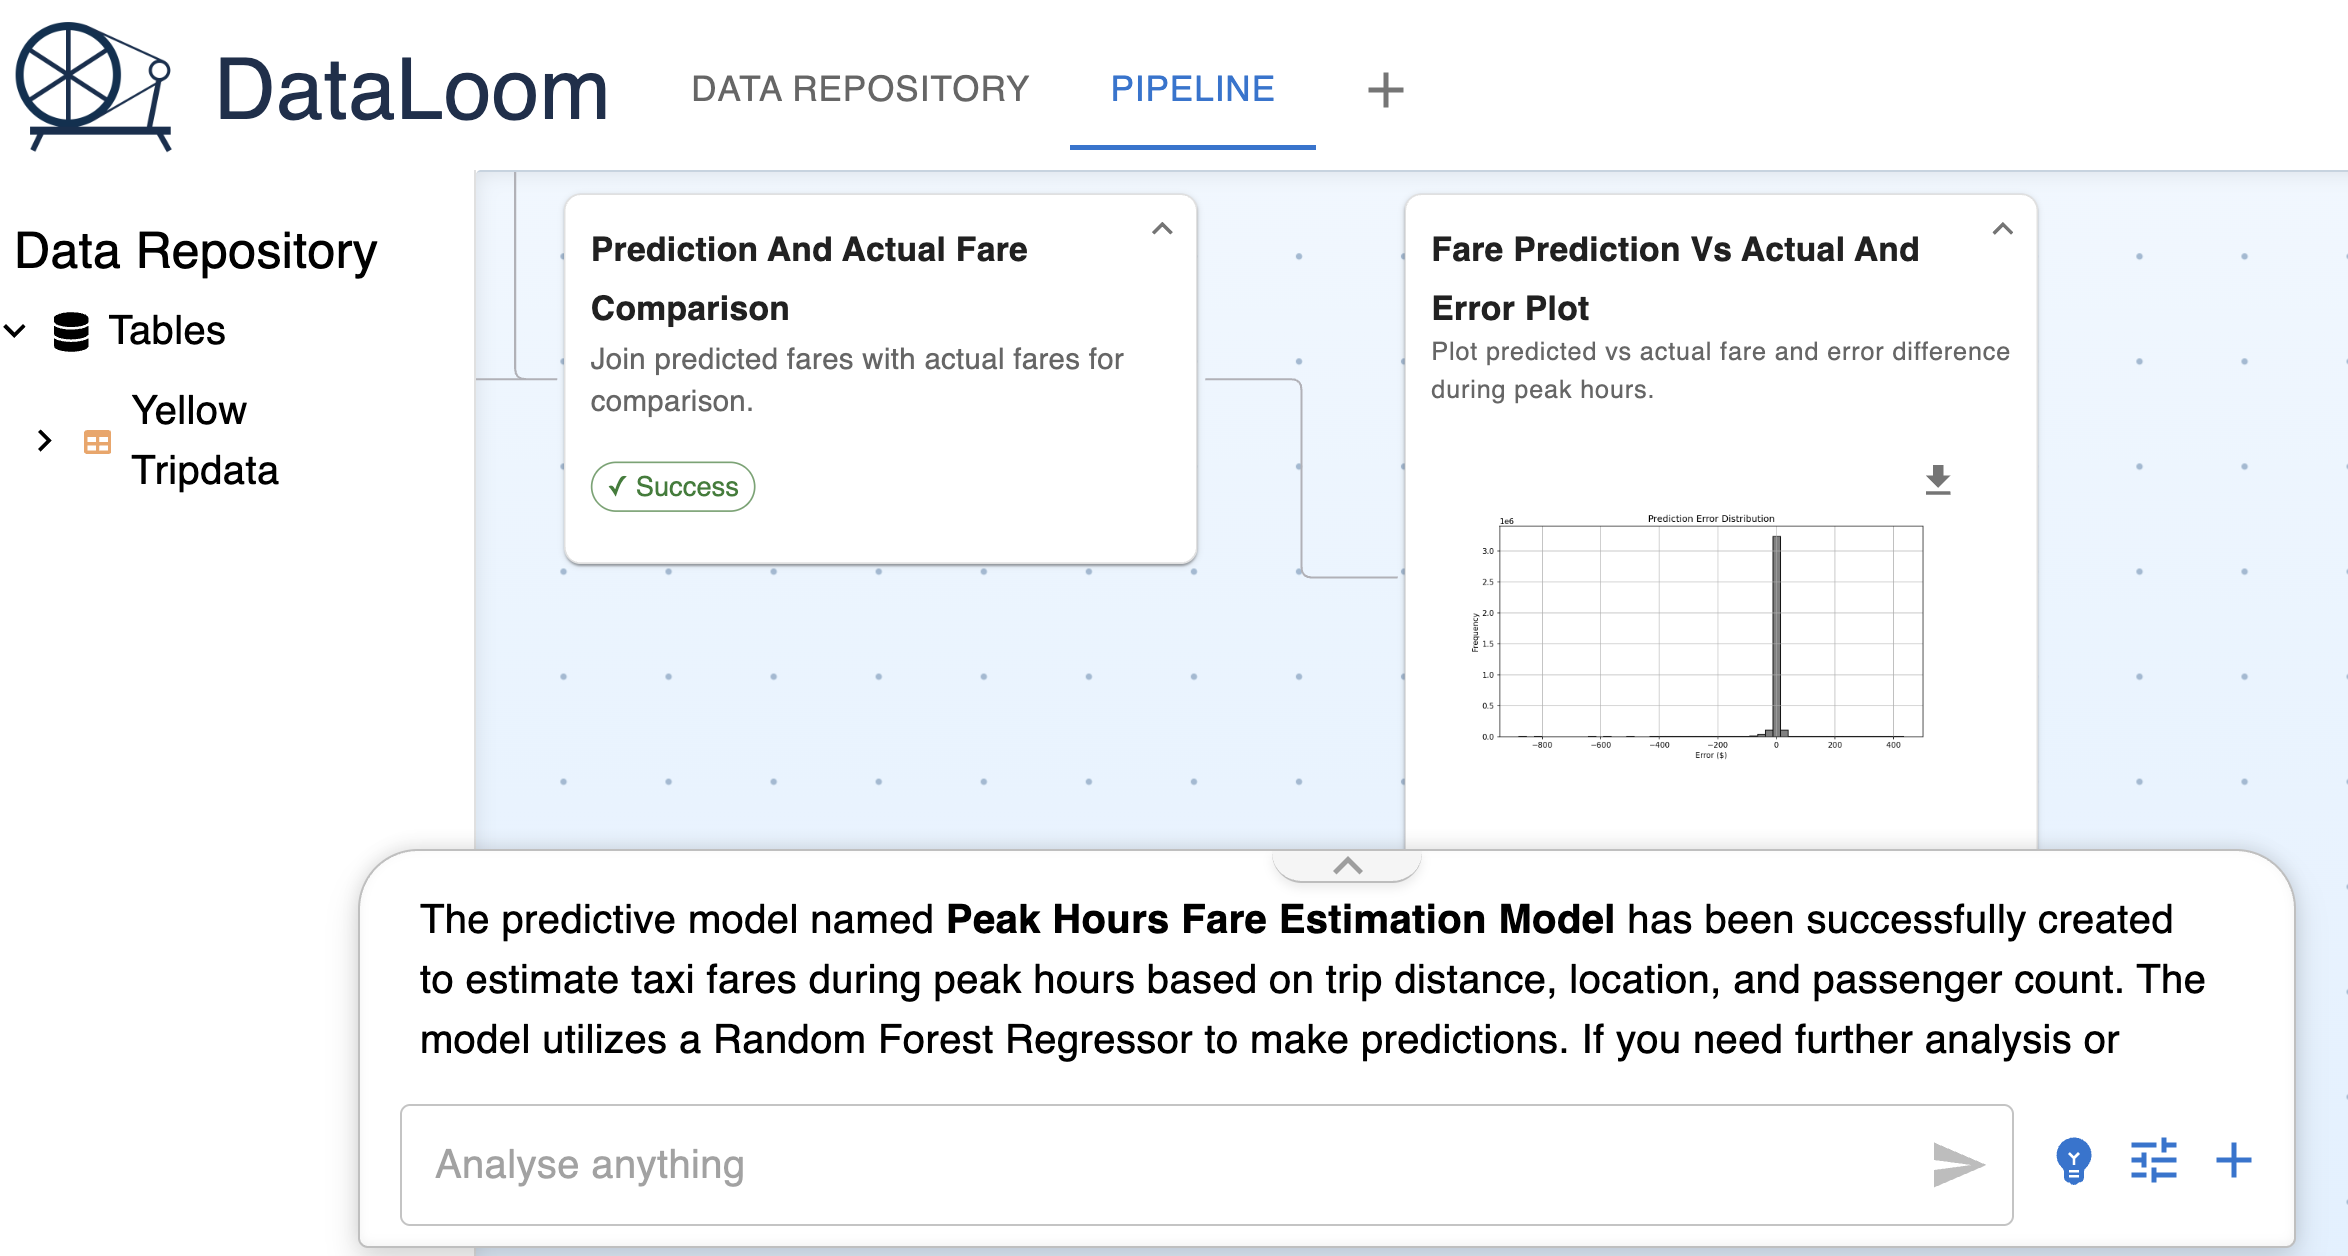

You should have received instructions on how to log in to DataLoom.  
*Note: You need to be connected to the university’s VPN.*

You can load the same New York City Taxi Dataset used earlier by typing the following command into the chat:

> load /data/students/nytd

Try solving some of the earlier tasks using DataLoom. How well does it perform? Do you encounter any bugs?

**Hints:**
1. DataLoom is still an early research prototype, so please be patient. If you encounter any bugs or issues, don’t hesitate to reach out—we’re happy to hear your feedback (and we have gummy bear rewards ready!).  
2. Some queries, especially those involving modeling or prediction, may take time and can temporarily cause DataLoom to become unresponsive 😬. If problems persist, contact us and we can restart your instance.  
3. If something seems broken, you can always refresh the website or restart your DataLoom instance (in *Settings*). Restarting clears the current state, allowing you to start fresh.  
4. DataLoom can also explain and answer questions about nodes. For example: “Please explain the ‘Cleaned Trip Distance’ node.”  
5. If a node shows an error, you can try to fix it manually or ask DataLoom to correct it. Unnecessary nodes can be deleted.  
6. You can also explore other datasets by dragging and dropping them onto the website.  


#### Task 6

Use DataLoom to answer the following questions:

1. First, clean the *trip distance* column by removing outliers. Double-check the code generated by DataLoom — does the outlier detection make sense? Can you think of cases that DataLoom might have missed? Try visualizing the data before and after cleaning, for example: “Please plot the trip distances …”.  
2. Detect time-localized surges (anomalously slow trips). There might be a traffic jam!  
3. Plot or inspect the results — do they make sense? Generate a report showing the “top anomalies.”  


## Feedback (voluntary)

How did you like this exercise? What could be improved?

Answer:
It was a fun little excercise but, it whould have been better if it involed some join related tasks. would have been more fun and interesting.

...

In addition, I feel that:
 - [X] The exercise was too easy.
 - [ ] The exercise was too hard.
 - [ ] The exercise was just right.
 - [ ] No answer.
